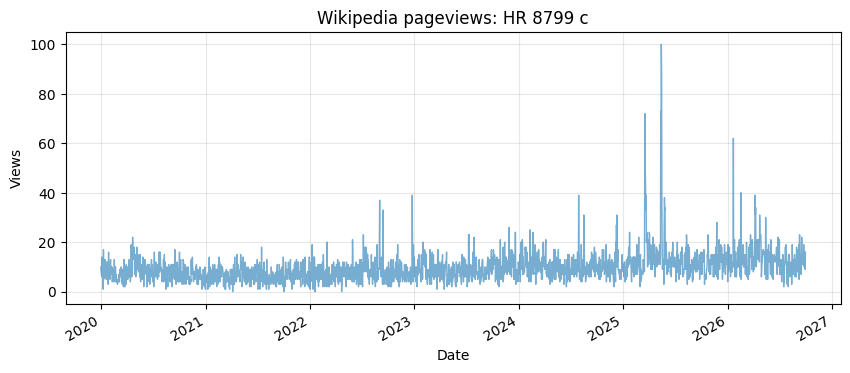

2020-01-01    10
2020-01-02     8
2020-01-03     7
2020-01-04     6
2020-01-05    14
              ..
2026-09-26    10
2026-09-27    12
2026-09-28    12
2026-09-29     9
2026-09-30    16
Name: HR_8799_c, Length: 2465, dtype: int64

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import scipy.stats as stats
import scipy.linalg as linalg
import seaborn as sns
from datetime import datetime, timedelta

import sys
sys.path.insert(0, '..')
from popularity_queries import pytrends_query, wiki_pageviews

exoplanets = pd.read_csv('../data/exoplanet_list.csv')

def article_name_getter(url):
    """
    Extracts the article name from a Wikipedia URL.
    """
    return url.split('wiki/')[-1]

def populate_basic_viewcounts(exoplanets):
    """
    Populates the exoplanets DataFrame with Wikipedia pageview counts.
    """
    i = 0
    while(i < len(exoplanets)):
       url = exoplanets.loc[i, '0'].split("', '")[-1]
       url = url.split("'")[0]
       name = article_name_getter(url)
       views = wiki_pageviews([name])
       view = views.sum(axis = 0).astype(int)
       exoplanets.loc[i, 'view_count'] = view.loc[name]
       i += 1

    return exoplanets



((wiki_pageviews(['Gliese_504_b']).sum(axis=0)).astype(int)).loc['Gliese_504_b']
exoplanets_views = populate_basic_viewcounts(exoplanets)



In [ ]:
def get_article_name(exoplanets, i):
    """Extracts the Wikipedia article name from row i of the exoplanets DataFrame."""
    url = exoplanets.loc[i, '0'].split("', '")[-1]
    url = url.split("'")[0]
    return article_name_getter(url)


def plot_viewcounts(exoplanets, planet, rolling=None):
    """
    Plots daily Wikipedia pageviews for a single exoplanet.

    planet:  a row index (int) into exoplanets, or an article name (str)
    rolling: optional window (in days) for a smoothed overlay, e.g. 7 or 30
    """
    name = get_article_name(exoplanets, planet) if isinstance(planet, int) else planet

    views = wiki_pageviews([name])
    series = views[name]
    series.index = pd.to_datetime(series.index.astype(str), format='%Y%m%d%H') #Temporary I hope hope hope

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(series.index, series.values, linewidth=1, alpha=0.6, label='Daily views')
    if rolling:
        ax.plot(series.index, series.rolling(rolling).mean(),
                linewidth=2, label=f'{rolling}-day average')
        ax.legend()

    ax.set_title(f'Wikipedia pageviews: {name.replace("_", " ")}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Views')
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    plt.show()

    return series

plot_viewcounts(exoplanets, 5)   

NameError: name 'exoplanets_views' is not defined

In [29]:
import ast
import re
import pandas as pd

views = pd.read_csv('exoplanet_views.csv', index_col=0)
please_be_right = pd.read_csv('exoplanets.csv')

views[['wiki_name', 'url']] = views['0'].apply(ast.literal_eval).apply(pd.Series) #why is pandas so weird

nasa = please_be_right[please_be_right['default_flag'] == 1]

# 3. Normalize names on both sides
REPLACEMENTS = {
    'gliese': 'gj',
    'epsilon': 'eps',
    'alpha': 'alf',
    'beta': 'bet',
    'kappa': 'kap',
}

def normalize(name):
    ''' Ill add the pydoc latter I swear'''
    name = name.lower()
    name = re.sub(r'[†?()]', '', name)        # daggers, (?), parentheses
    for long, short in REPLACEMENTS.items():
        name = name.replace(long, short)
    return re.sub(r'\s+', '', name)           # drop all whitespace

views['key'] = views['wiki_name'].apply(normalize)
nasa['key'] = nasa['pl_name'].apply(normalize)

# 4. Merge
merged = views.merge(nasa[['key', 'pl_name', 'pl_rade']], on='key', how='left')

# 5. See what didn't match
unmatched = merged[merged['pl_name'].isna()]['wiki_name']
#print(f'{len(unmatched)} unmatched:')
#print(unmatched.to_string())

result = merged[['wiki_name', 'pl_name', 'pl_rade', 'view_count']].dropna(subset=['pl_rade', 'view_count'])


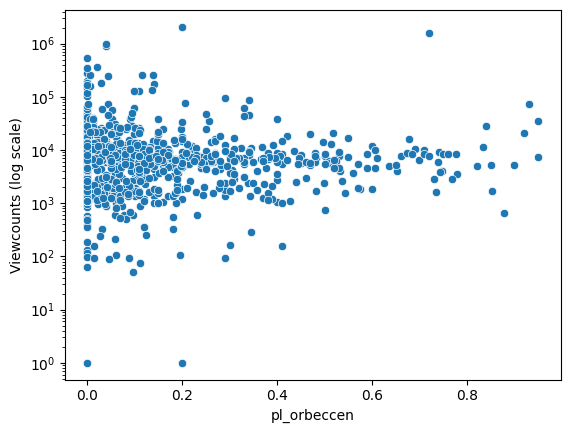

In [42]:

import seaborn as sns
import matplotlib.pyplot as plt
def physical_properties_view_graph(property):
    '''given a property from exoplanets.csv, returns a graph of that property verses viewcount. Also prints out the
    R value, slope, and p-value of a sig test on slope'''
    merged = views.merge(nasa[['key', 'pl_name', property]], on='key', how='left')
    result = merged.dropna(subset=[property, 'view_count'])
    sns.scatterplot(x = result[property], y = result['view_count'])
    plt.xlabel(property)
    plt.ylabel("Viewcounts (log scale)")
    plt.yscale("log")
physical_properties_view_graph("pl_orbeccen")
